## 1️⃣ Introduction

The Cafe Sales – Dirty Data for Cleaning Training dataset contains transactional data from a fictional café. The dataset was intentionally created with inconsistencies, missing values, and formatting issues to simulate real-world messy data.

The purpose of this project is to practice data cleaning, exploration, and analysis using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn.

### Analysis Goals

#### In this notebook we aim to:

- Clean and preprocess the dataset

- Handle missing and inconsistent data

- Perform exploratory data analysis (EDA)

- Identify sales patterns and trends

- Visualize important insights from the data

#### Key questions explored in this analysis include:

- What are the most popular items sold in the café?

- Which payment methods are used the most?

- What time periods generate the highest sales?

- What products generate the most revenue?

## 2️⃣ Import Libraries

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3️⃣ Load the Dataset

In [2]:
path = kagglehub.dataset_download("ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training")
df = pd.read_csv(path + "/dirty_cafe_sales.csv")

Using Colab cache for faster access to the 'cafe-sales-dirty-data-for-cleaning-training' dataset.


In [3]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 4️⃣ Data Understanding

In [4]:
df.shape

(10000, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [6]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [7]:
df.isnull().sum()

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


In [8]:
df.duplicated().sum()

np.int64(0)

## 5️⃣ Data Cleaning

In [33]:
df.fillna("Unknown", inplace=True)

In [34]:
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"], errors='coerce')
df["Quantity"] = pd.to_numeric(df["Quantity"], errors='coerce')
df["Price Per Unit"] = pd.to_numeric(df["Price Per Unit"], errors='coerce')

## 6️⃣ New colums

In [46]:
df["Total Sales"] = df["Quantity"] * df["Price Per Unit"]
df["Month"] = df["Transaction Date"].dt.month
df["Day"] = df["Transaction Date"].dt.day_name()

## 7️⃣ KPI's

In [47]:
product_sales = df.groupby("Item")["Total Sales"].sum().sort_values(ascending=False)
product_sales.head()

,Total Sales
Item,
Salad,15600.0
Sandwich,12296.0
Smoothie,12132.0
Juice,9561.0
Cake,9540.0


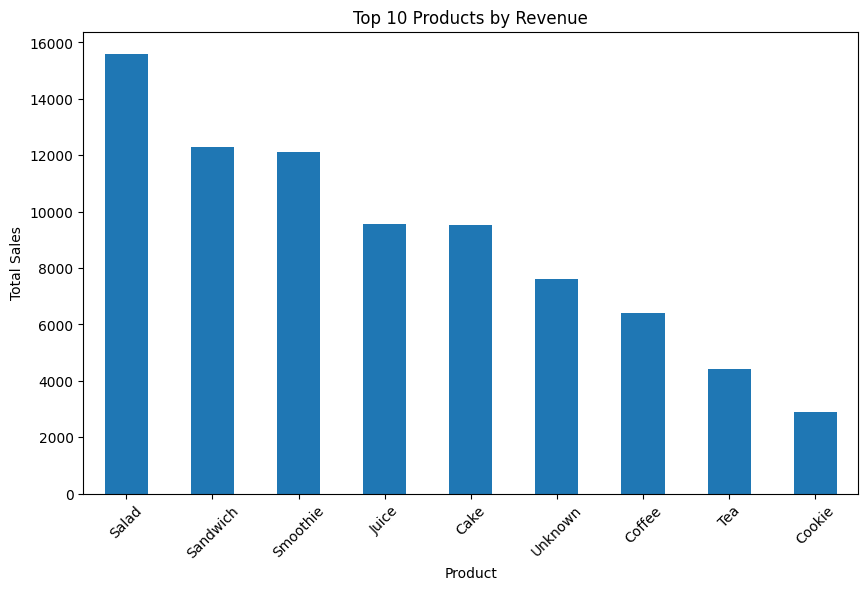

In [48]:
plt.figure(figsize=(10,6))
product_sales.head(10).plot(kind="bar")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [49]:
popular_items = df["Item"].value_counts()
popular_items.head()

,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131


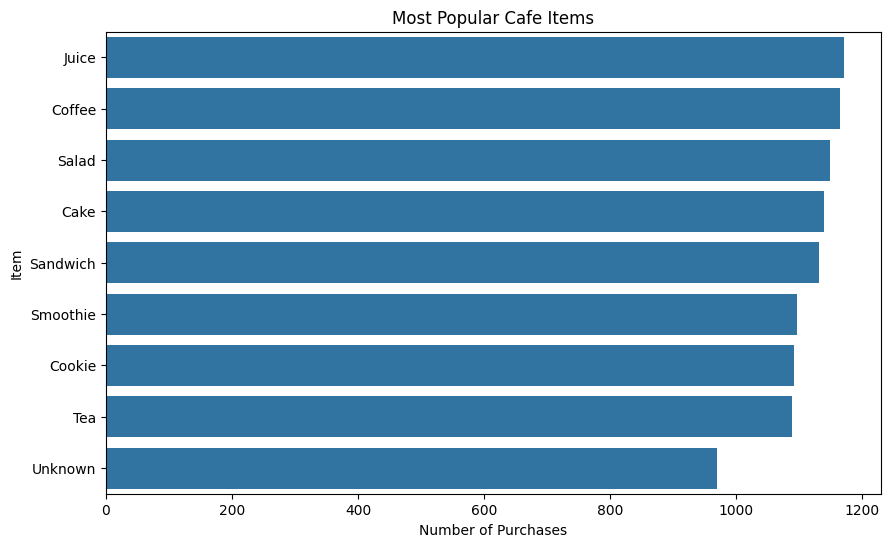

In [50]:
plt.figure(figsize=(10,6))
sns.barplot(x=popular_items.head(10).values,
            y=popular_items.head(10).index)

plt.title("Most Popular Cafe Items")
plt.xlabel("Number of Purchases")
plt.ylabel("Item")

plt.show()

In [51]:
payment_counts = df["Payment Method"].value_counts()
payment_counts

,count
Payment Method,
Unknown,3178
Digital Wallet,2291
Credit Card,2273
Cash,2258


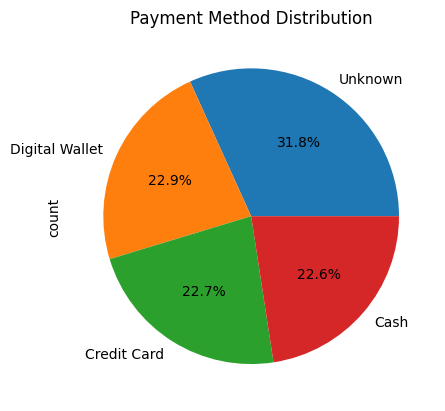

In [52]:
payment_counts.plot(kind="pie", autopct="%1.1f%%")
plt.title("Payment Method Distribution")
plt.show()

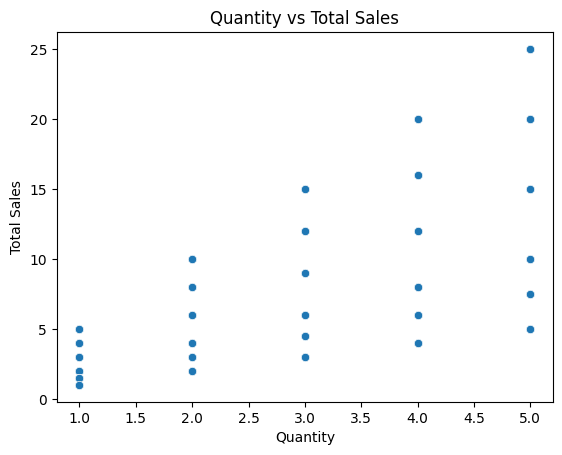

In [53]:
sns.scatterplot(x="Quantity", y="Total Sales", data=df)
plt.title("Quantity vs Total Sales")
plt.show()

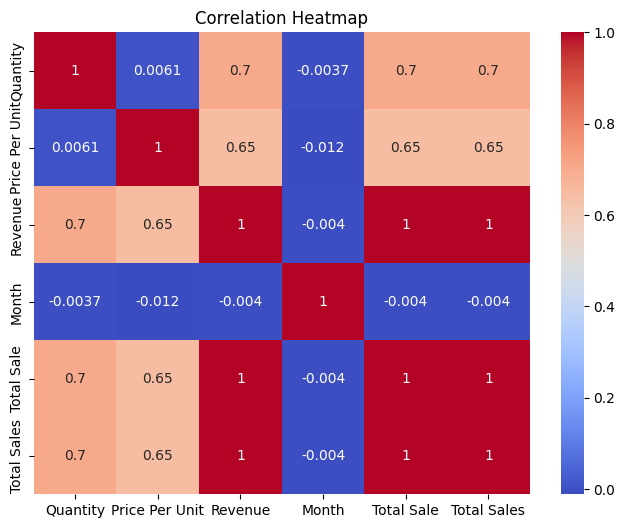

In [54]:
numeric_cols = df.select_dtypes(include=np.number)
corr = numeric_cols.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")

plt.show()

## 9 Conclusion

This project demonstrated the full data analysis workflow using the Café Sales dataset.

Key steps included:
- Understanding the dataset structure
- Cleaning inconsistent and missing data
- Performing exploratory data analysis
- Creating visualizations to identify patterns

The analysis revealed insights into product popularity, revenue generation, and customer payment behavior.

Future work could include:
- Time series analysis of sales trends
- Predicting high-revenue products
- Customer segmentation